In [5]:
import kagglehub
path = kagglehub.dataset_download("shaunthesheep/microsoft-catsvsdogs-dataset")

Using Colab cache for faster access to the 'microsoft-catsvsdogs-dataset' dataset.


In [6]:
import os

print(f"Dataset downloaded to: {path}")
# List the contents of the downloaded dataset directory
if os.path.exists(path):
    print("\nDirectory contents:")
    display(os.listdir(path))
else:
    print("Path does not exist.")

Dataset downloaded to: /kaggle/input/microsoft-catsvsdogs-dataset

Directory contents:


['PetImages', 'readme[1].txt', 'MSR-LA - 3467.docx']

In [24]:
import os
import shutil
import tensorflow as tf

clean_base_dir = '/content/clean_images'
if os.path.exists(clean_base_dir):
    shutil.rmtree(clean_base_dir)
os.makedirs(clean_base_dir, exist_ok=True)

num_copied = 0
num_skipped = 0

for folder_name in ['Cat', 'Dog']:
    src_folder = os.path.join(path, 'PetImages', folder_name)
    dest_folder = os.path.join(clean_base_dir, folder_name)
    os.makedirs(dest_folder, exist_ok=True)

    for fname in os.listdir(src_folder):
        fpath = os.path.join(src_folder, fname)
        try:
            if os.path.getsize(fpath) == 0:
                num_skipped += 1
                continue

            # Read file bytes
            with open(fpath, 'rb') as f:
                img_bytes = f.read()

            # Try decoding with TensorFlow to ensure it won't crash during training
            tf.io.decode_jpeg(img_bytes, channels=3)

            # If successful, copy to the clean directory
            shutil.copy(fpath, os.path.join(dest_folder, fname))
            num_copied += 1
        except Exception:
            num_skipped += 1

print(f"Successfully copied {num_copied} valid images. Skipped {num_skipped} corrupt files.")
dataset_dir = clean_base_dir

Successfully copied 24824 valid images. Skipped 178 corrupt files.


In [33]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, Flatten, MaxPooling2D, BatchNormalization,Dropout

In [25]:
import os

# We point directly to our clean directory containing the 'Cat' and 'Dog' folders
# dataset_dir is set to '/content/clean_images'

# Create training dataset (80%)
train_ds = keras.utils.image_dataset_from_directory(
    directory=dataset_dir,
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256),
    validation_split=0.2,
    subset='training',
    seed=123
)

# Create validation dataset (20%)
val_ds = keras.utils.image_dataset_from_directory(
    directory=dataset_dir,
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256),
    validation_split=0.2,
    subset='validation',
    seed=123
)

Found 24824 files belonging to 2 classes.
Using 19860 files for training.
Found 24824 files belonging to 2 classes.
Using 4964 files for validation.


In [26]:
# normailze

def process(image,label):
  image= tf.cast(image/255, tf.float32)
  return image,label

train_ds = train_ds.map(process)
val_ds= val_ds.map(process)

In [36]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3), padding= 'valid', activation='relu', input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Conv2D(64, kernel_size=(3,3), padding='valid', activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Conv2D(128, kernel_size=(3,3), padding='valid', activation = 'relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [38]:
model.compile(optimizer='adam', loss= 'binary_crossentropy', metrics=['accuracy'])

In [39]:
history = model.fit(train_ds, epochs =10, validation_data=val_ds)

Epoch 1/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 73s 105ms/step - accuracy: 0.6150 - loss: 1.2619 - val_accuracy: 0.6628 - val_loss: 0.6484
Epoch 2/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 61s 99ms/step - accuracy: 0.7280 - loss: 0.5520 - val_accuracy: 0.5689 - val_loss: 0.7245
Epoch 3/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 61s 99ms/step - accuracy: 0.7739 - loss: 0.4719 - val_accuracy: 0.7530 - val_loss: 0.5032
Epoch 4/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.8091 - loss: 0.4218 - val_accuracy: 0.6541 - val_loss: 0.6327
Epoch 5/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 85s 99ms/step - accuracy: 0.8303 - loss: 0.3871 - val_accuracy: 0.7855 - val_loss: 0.4967
Epoch 6/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.8756 - loss: 0.2886 - val_accuracy: 0.7780 - val_loss: 0.5198
Epoch 7/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.9032 - loss: 0.2221 - val_accuracy: 0.7629 - val_loss: 0.6358
Epoch 8/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.9372 - loss: 0.1586 -

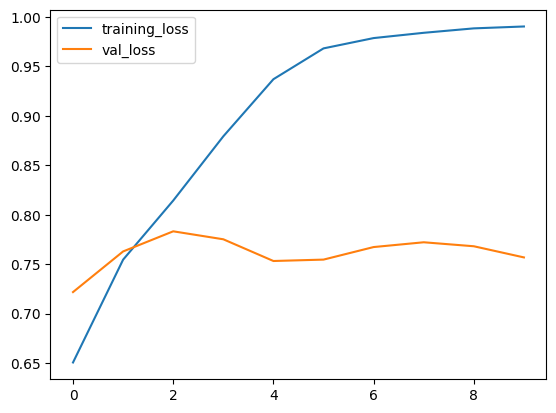

In [31]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='training_loss')
plt.plot(history.history['val_accuracy'], label='val_loss')
plt.legend()
plt.show()

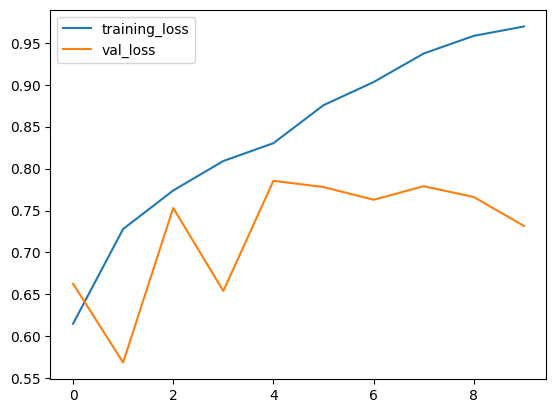

In [41]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='training_loss')
plt.plot(history.history['val_accuracy'], label='val_loss')
plt.legend()
plt.show()

In [42]:
import cv2

In [43]:
test_img = cv2.imread('/kaggle/input/microsoft-catsvsdogs-dataset/PetImages/Cat/10064.jpg')

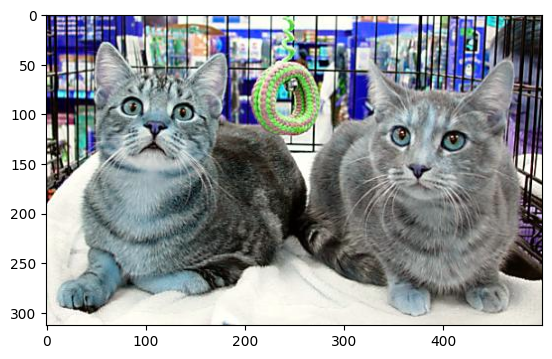

In [44]:
plt.imshow(test_img)